In [1]:
import pandas as pd
cat = pd.read_csv("../data/catalog.csv")

In [2]:
cat.shape

(281, 26)

In [3]:
print(cat.release.value_counts(), "\n")
print(cat.response_type.value_counts(), "\n")
print(cat.granularity.value_counts())

release
public      278
withheld      3
Name: count, dtype: int64 

response_type
binary                  163
mixed                    49
continuous_bounded       17
continuous               14
ordinal                  14
fraction                  8
likert_5                  6
continuous_unbounded      5
nominal                   2
win_rate                  2
likert_10                 1
Name: count, dtype: int64 

granularity
item    281
Name: count, dtype: int64


In [4]:
# binary benchmarks limited. 

usable = cat[(cat.release == "public") & (cat.response_type == "binary") & (cat.granularity == "item")]

In [5]:
print(len(usable), "usable benchmarks")

160 usable benchmarks


In [6]:
usable.columns

Index(['dir', 'benchmark_id', 'name', 'version', 'license', 'source_url',
       'description', 'one_line_description', 'modality', 'domain',
       'multi_single_turn', 'response_type', 'response_scale', 'categorical',
       'paper_url', 'release_date', 'granularity', 'release',
       'n_response_values', 'benchmark_features', 'n_subjects', 'n_items',
       'n_responses', 'max_trial', 'coverage', 'has_reference_answer'],
      dtype='str')

In [7]:
cols = ["dir", "n_subjects", "n_items", "n_responses"]
print(usable[cols].sort_values("n_subjects", ascending=False).head(15).to_string(index=False))
print(usable[cols].sum(numeric_only=True))

                    dir  n_subjects  n_items  n_responses
       alignment_faking        4278     1464      2138969
                 sib200        3343    83640       765204
                  haiid        1126      152        71364
               afrieval         948    35205      1403380
           bridging_gap         417   132418      4706881
         mathvista_mini         263     1000       285000
         hallusionbench         254     1205       240857
              ai2d_test         254     3088       784352
           mmmu_dev_val         253     1050       265650
            mmbench_v11         251    12175      3262900
                    ikp         170     1400       268351
                   mmlu         150    14015      2106300
          truthfulqa_mc         150      817       122550
               bird_sql         120      360        43200
llms_lean_formalization         120      588        64960
n_subjects        14798
n_items         4867356
n_responses    71049402


In [8]:
t = "../data/raw/ikp/formatted_tables/"
subjects = pd.read_parquet(t + "subjects.parquet")
items = pd.read_parquet(t + "items.parquet")
responses = pd.read_parquet(t + "responses.parquet")
print(subjects.shape, items.shape, responses.shape)
subjects.head(3)


(170, 10) (1400, 9) (268351, 8)


,subject_id,display_name,normalized_name,provider,release_date,access_date,harness,reasoning_effort,harness_version,subject_features_extra
0,d6ec2555f79d0d80,claude-3-haiku,Anthropic Claude 3 Haiku,Anthropic,2024-03-04,NaN,NaN,NaN,NaN,NaN
1,b64aeb51ffc92d29,claude-3.5-haiku,Anthropic Claude 3.5 Haiku,Anthropic,2024-10-22,NaN,NaN,NaN,NaN,NaN
2,7fcaa05b8c908c9f,claude-3.7-sonnet-think,Anthropic Claude 3.7 Sonnet,Anthropic,2025-02-24,NaN,NaN,NaN,NaN,NaN


In [10]:
items.head(3)

,item_id,benchmark_id,raw_item_id,content,asset_manifest,grading_criterion,verifier,content_hash,item_features
0,b4e25751c476d271,ikp,IKP_T1_0000,What strait separates Sicily from mainland Italy?,NaN,"{""reference_answer"":""Strait of Messina"",""rule""...","{""class"": ""judge"", ""judged_by"": ""llm"", ""spec"":...",e45f4b5de385c4b3,NaN
1,906e61d7f72745e4,ikp,IKP_T1_0001,What is the capital of Canada?,NaN,"{""reference_answer"":""Ottawa"",""rule"":""The upstr...","{""class"": ""judge"", ""judged_by"": ""llm"", ""spec"":...",e0a8329cfe23fa79,NaN
2,f91d9d3ca2d1e8bc,ikp,IKP_T1_0002,What is the capital of France?,NaN,"{""reference_answer"":""Paris"",""rule"":""The upstre...","{""class"": ""judge"", ""judged_by"": ""llm"", ""spec"":...",115049a298532be2,NaN


In [11]:
items[["item_id", "content", "item_features"]].head(3)

,item_id,content,item_features
0,b4e25751c476d271,What strait separates Sicily from mainland Italy?,NaN
1,906e61d7f72745e4,What is the capital of Canada?,NaN
2,f91d9d3ca2d1e8bc,What is the capital of France?,NaN


In [12]:
responses.head(3)

,subject_id,item_id,response_id,benchmark_id,trial,test_condition,interactors,response
0,d6ec2555f79d0d80,b4e25751c476d271,01101a5da6fe6aae,ikp,1,NaN,NaN,1.0
1,d6ec2555f79d0d80,906e61d7f72745e4,ea58211d6adced13,ikp,1,NaN,NaN,1.0
2,d6ec2555f79d0d80,f91d9d3ca2d1e8bc,b463dd8c11ff1a9a,ikp,1,NaN,NaN,1.0


A subject is a model configuration with a hashed subject_id.

an item is one question with a hashed item_id

a response row join the two with a trial number and 0/1 response. 

In [13]:
joined = (responses[["subject_id", "item_id", "trial", "response"]]
          .merge(subjects[["subject_id", "normalized_name", "provider", "release_date"]], on="subject_id")
          .merge(items[["item_id", "content"]], on="item_id"))
print(joined.shape)
joined.head(5)

(268351, 8)


,subject_id,item_id,trial,response,normalized_name,provider,release_date,content
0,d6ec2555f79d0d80,b4e25751c476d271,1,1.0,Anthropic Claude 3 Haiku,Anthropic,2024-03-04,What strait separates Sicily from mainland Italy?
1,d6ec2555f79d0d80,906e61d7f72745e4,1,1.0,Anthropic Claude 3 Haiku,Anthropic,2024-03-04,What is the capital of Canada?
2,d6ec2555f79d0d80,f91d9d3ca2d1e8bc,1,1.0,Anthropic Claude 3 Haiku,Anthropic,2024-03-04,What is the capital of France?
3,d6ec2555f79d0d80,749b5d1dc9d650af,1,1.0,Anthropic Claude 3 Haiku,Anthropic,2024-03-04,In what year was the Brooklyn Bridge opened?
4,d6ec2555f79d0d80,92784f83e5391365,1,1.0,Anthropic Claude 3 Haiku,Anthropic,2024-03-04,What is the capital of Portugal?


In [17]:
print("responses NaN:", responses.response.isna().sum(), "of", len(responses))
print("response values:", responses.response.dropna().unique())
print("trials per pair:", responses.groupby(["subject_id", "item_id"]).size().value_counts().to_dict())
print("\nsubject columns filled (%):")
print((subjects.apply(lambda c: (c.notna() & (c.astype(str).str.strip() != "")).mean()) * 100).round(1))


responses NaN: 0 of 268351
response values: [1. 0.]
trials per pair: {1: 185125, 2: 40032, 3: 1054}

subject columns filled (%):
subject_id                100.0
display_name              100.0
normalized_name           100.0
provider                  100.0
release_date              100.0
access_date                 0.0
harness                     0.0
reasoning_effort            0.0
harness_version             0.0
subject_features_extra      0.0
dtype: float64


In [19]:
rows = []
for p in sorted(glob.glob("../data/raw/*/formatted_tables/subjects.parquet")):
    s = pd.read_parquet(p)
    filled = s.apply(lambda c: (c.notna() & (c.astype(str).str.strip() != "")).mean())
    rows.append({"benchmark": p.split("/")[-3].split("\\")[-1], "n_subjects": len(s), **filled.round(2).to_dict()})
fill = pd.DataFrame(rows)
cols = [c for c in fill.columns if c not in ("benchmark", "n_subjects", "subject_id")]
print("fraction of benchmarks where the field is filled for most subjects:")
print((fill[cols] > 0.5).mean().round(2).sort_values(ascending=False)) # fraction of benchmarks where the field is filled for more than 50% of subjects


fraction of benchmarks where the field is filled for most subjects:
display_name              1.00
subject_features_extra    0.88
harness                   0.86
normalized_name           0.59
provider                  0.59
release_date              0.59
harness_version           0.04
access_date               0.02
reasoning_effort          0.01
dtype: float64


In [21]:
from pathlib import Path
rows = []
for p in sorted(glob.glob("../data/raw/*/formatted_tables/subjects.parquet")):
    s = pd.read_parquet(p)
    filled = s.apply(lambda c: (c.notna() & (c.astype(str).str.strip() != "")).mean())
    rows.append({"benchmark": Path(p).parts[-3], "n_subjects": len(s), **filled.round(2).to_dict()})
fill = pd.DataFrame(rows)
fill.head(3)


,benchmark,n_subjects,subject_id,display_name,normalized_name,provider,release_date,access_date,harness,reasoning_effort,harness_version,subject_features_extra
0,abstract_reason,1,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
1,adaptivestep,3,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,advprompter,2,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0


In [22]:
fill

,benchmark,n_subjects,subject_id,display_name,normalized_name,provider,release_date,access_date,harness,reasoning_effort,harness_version,subject_features_extra
0,abstract_reason,1,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
1,adaptivestep,3,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,advprompter,2,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3,aegis,1,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
4,afrieval,948,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
155,wikihow_agent,12,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
156,wmt_mqm,113,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
157,workarena,8,1.0,1.0,0.5,0.5,0.5,0.0,1.0,0.0,0.0,1.0
158,workbench_revisited,24,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0


In [25]:
for b in empty[:3]:
    s = pd.read_parquet(f"../data/raw/{b}/formatted_tables/subjects.parquet")
    print(b, "|", s.display_name.iloc[0], "|", str(s.subject_features_extra.iloc[0])[:200])


adaptivestep | MetaMath-Llama | model_identifier=MetaMath-Llama
afrieval | XLM-R | dataset_version=v1;evaluation_language=amh;released_run=released_single_export;source_export=upstream/entity_analysis/XLM-R/amh_xlmr_test_predictions.txt;source_model_label=XLM-R
alpha_sql | Qwen/Qwen2.5-Coder-32B-Instruct | exploration_constant=1.414;max_depth=16;max_rollout_steps=24;max_tokens=4096;model_identifier=Qwen/Qwen2.5-Coder-32B-Instruct;n=3;n_strategy=single;top_p=0.8


In [26]:
import re
fmt = {"json": 0, "kv": 0, "other": 0}; has_name = 0; total = 0
for b in empty:
    s = pd.read_parquet(f"../data/raw/{b}/formatted_tables/subjects.parquet")
    for v in s.subject_features_extra.dropna().astype(str):
        total += 1
        if v.startswith("{"): fmt["json"] += 1
        elif "=" in v: fmt["kv"] += 1
        else: fmt["other"] += 1
        if re.search(r"(model_identifier|source_model_label|model_name|source_model|base_model)=|\"(model_identifier|source_model_label|model_name|source_model|base_model)\"", v):
            has_name += 1
print(fmt, "| rows with a name key:", has_name, "of", total)


{'json': 0, 'kv': 7930, 'other': 0} | rows with a name key: 5885 of 7930


In [27]:
pivot = responses.pivot_table(index="subject_id", columns="item_id", values="response", aggfunc="mean")
print(pivot.shape, "| filled:", f"{pivot.notna().mean().mean():.0%}")
print("subject accuracy: mean %.2f, std %.2f" % (pivot.mean(axis=1).mean(), pivot.mean(axis=1).std()))
print("item accuracy:    mean %.2f, std %.2f" % (pivot.mean(axis=0).mean(), pivot.mean(axis=0).std()))
pivot.iloc[:8, :8]


(170, 1400) | filled: 95%
subject accuracy: mean 0.58, std 0.16
item accuracy:    mean 0.56, std 0.36


item_id,000583fb533cb28a,001d25ca73a2ea0f,0052981c8c85aec3,005c0876f7bd69d5,00678bdbc9243304,007343a03828b4d0,00cfc4e8486d1986,00f3119170a65e8e
subject_id,,,,,,,,
00b74e46dc69680f,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
0124d3848a9d6ca9,1.0,1.0,1.0,1.0,1.0,0.5,1.0,1.0
03bd005b517187a5,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
04a4a46dbc2662cf,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0
051fb5689a9fa34b,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
08b8a8b57237045f,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
092a1a339e59aac2,1.0,1.0,0.0,1.0,1.0,0.5,1.0,1.0
0b4efa58cabcd468,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0


In [ ]:
pivot # subject x items. 

item_id,000583fb533cb28a,001d25ca73a2ea0f,0052981c8c85aec3,005c0876f7bd69d5,00678bdbc9243304,007343a03828b4d0,00cfc4e8486d1986,00f3119170a65e8e,012f6e4e97e9f756,015dc6785c1c3505,...,fde6c337020bbeff,fe107304088f0665,fe478e6733438c63,fe7f10008c7cf0c0,fed6c3e04bd0fd48,ff02cf4d9bf75232,ff566cb257d729b2,ff60abf60eae94b3,ff7e89b3ec4da906,ffc48496b95c5bfc
subject_id,,,,,,,,,,,,,,,,,,,,,
00b74e46dc69680f,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,...,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0
0124d3848a9d6ca9,1.0,1.0,1.0,1.0,1.0,0.5,1.0,1.0,0.0,0.5,...,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0
03bd005b517187a5,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0
04a4a46dbc2662cf,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0
051fb5689a9fa34b,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
fb756c177643c16c,1.0,1.0,0.0,1.0,1.0,0.5,0.5,1.0,0.0,0.0,...,0.0,0.5,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0
fb91c581a3ab32b5,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0
fbb1b08604d0dcaa,1.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0


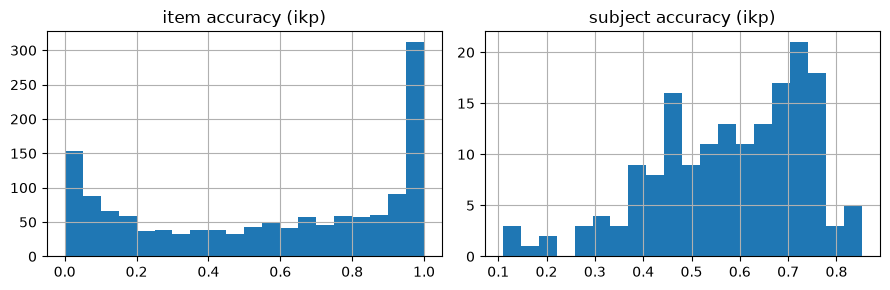

In [29]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
pivot.mean(axis=0).hist(bins=20, ax=ax[0]); ax[0].set_title("item accuracy (ikp)")
pivot.mean(axis=1).hist(bins=20, ax=ax[1]); ax[1].set_title("subject accuracy (ikp)")
plt.tight_layout()


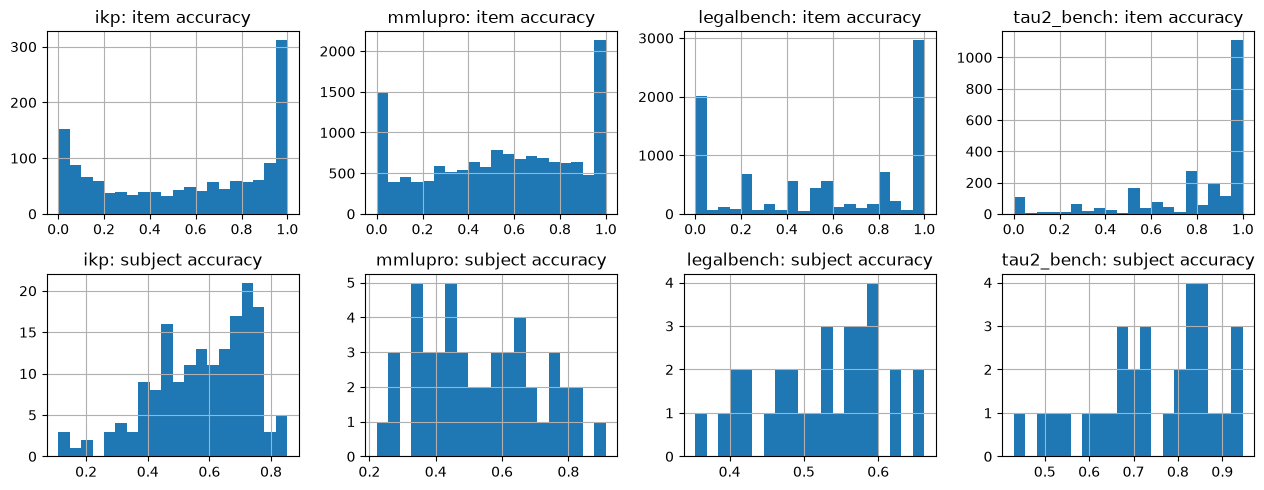

: 

In [ ]:
names = ["ikp", "mmlupro", "legalbench", "tau2_bench"]
fig, axes = plt.subplots(2, len(names), figsize=(3.2 * len(names), 5))
for j, b in enumerate(names):
    r = pd.read_parquet(f"../data/raw/{b}/formatted_tables/responses.parquet").dropna(subset=["response"])
    pv = r.pivot_table(index="subject_id", columns="item_id", values="response", aggfunc="mean")
    pv.mean(axis=0).hist(bins=20, ax=axes[0, j]); axes[0, j].set_title(f"{b}: item accuracy")
    pv.mean(axis=1).hist(bins=20, ax=axes[1, j]); axes[1, j].set_title(f"{b}: subject accuracy")
plt.tight_layout()


Most questions seem to be answered by nearly every model or by nearly none, so the outcome of a pair is mostly decided by the item, not the subject. Subject accuracies form a single hump so knowing subject alone never gets close to certainty. 





the item shift needs other subjects cards on the same item at budget 31 a benchmark has 31 x number of subjets reveals spread over its itmes. ikp = 170 subjects 1400 items few reveals per items, legalbench 31 subjects 9400 items one reveal per 10 items so most eval items have no revelas form anyone. Coverage decides where pooling pays off but the platform has one or two subjects per benchmark means little coverage there. 